# 12 — Compare the four 0.5B models

Zero-shot (01) → SFT on gold (02) → SFT on own correct answers, RFT (05) → GRPO (06). Same greedy decoding, same prompts, so predictions are paired problem by problem.

**Inputs (*Add Input*):** the outputs of notebooks `01`, `02`, `05`, `06`. No GPU needed (CPU session is fine).
Shows: accuracy with paired-bootstrap 95% CI, format rate and length, paired flips with McNemar, and how many models solve each problem.

In [1]:
import json
from glob import glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

OUT_DIR = Path("/kaggle/working/exp12_compare_0.5b"); OUT_DIR.mkdir(parents=True, exist_ok=True)

RUNS = {
    "zero-shot": ("exp1_zeroshot_0.5b",      {"gsm8k": "predictions_gsm8k.jsonl",      "svamp": "predictions_svamp.jsonl"}),
    "gold SFT":  ("exp2_sft_0.5b",           {"gsm8k": "predictions_gsm8k.jsonl",      "svamp": "predictions_svamp.jsonl"}),
    "RFT SFT":   ("exp5_sft_rft_0.5b",       {"gsm8k": "predictions_gsm8k.jsonl",      "svamp": "predictions_svamp.jsonl"}),
    "GRPO":      ("exp6_grpo_0.5b",          {"gsm8k": "predictions_gsm8k_test.jsonl", "svamp": "predictions_svamp_test.jsonl"}),
}
MODELS, DATASETS, B = list(RUNS), ["gsm8k", "svamp"], 10_000

def is_correct(pred, gold):
    try:
        return pred is not None and abs(float(pred) - float(gold)) < 1e-6
    except ValueError:
        return False

def load(model, dataset):
    folder, files = RUNS[model]
    hits = glob(f"/kaggle/input/**/{folder}/{files[dataset]}", recursive=True)
    assert hits, f"{folder}/{files[dataset]} not found: add the notebook that produced it as an input"
    df = pd.read_json(hits[0], lines=True, dtype={"gold": str, "pred": str})
    df["correct"] = [is_correct(p, g) for p, g in zip(df.pred, df.gold)]
    if "has_format" not in df: df["has_format"] = df.response.str.contains("####")
    return df

preds = {d: {m: load(m, d) for m in MODELS} for d in DATASETS}
for d in DATASETS:                                   # paired: every model must have answered the same problems in the same order
    golds = [preds[d][m].gold.tolist() for m in MODELS]
    assert all(g == golds[0] for g in golds), f"{d}: problems differ between runs"
print({d: len(preds[d][MODELS[0]]) for d in DATASETS})

{'gsm8k': 1319, 'svamp': 1000}


## Accuracy, format, length
CI = paired bootstrap over problems (10,000 resamples).

In [2]:
rng = np.random.default_rng(42)
rows, boot = [], {}
for d in DATASETS:
    M = np.stack([preds[d][m].correct.to_numpy() for m in MODELS])          # (models, problems)
    idx = rng.integers(0, M.shape[1], (B, M.shape[1]))
    boot[d] = np.stack([M[i][idx].mean(-1) for i in range(len(MODELS))])  # (models, B) accuracies, same resamples for all models
    for i, m in enumerate(MODELS):
        df, lo, hi = preds[d][m], *np.percentile(boot[d][i], [2.5, 97.5])
        rows.append(dict(dataset=d, model=m, accuracy=100 * M[i].mean(), ci_low=100 * lo, ci_high=100 * hi,
                         format_rate=100 * df.has_format.mean(), mean_chars=df.response.str.len().mean()))
table = pd.DataFrame(rows)
table.round(1).to_csv(OUT_DIR / "comparison.csv", index=False)
table.round(1)

,dataset,model,accuracy,ci_low,ci_high,format_rate,mean_chars
0,gsm8k,zero-shot,43.7,41.0,46.5,16.5,1000.6
1,gsm8k,gold SFT,32.7,30.2,35.2,99.6,247.4
2,gsm8k,RFT SFT,49.4,46.7,52.0,94.4,1008.8
3,gsm8k,GRPO,54.4,51.7,57.1,94.4,1010.0
4,svamp,zero-shot,53.7,50.6,56.8,36.4,774.2
5,svamp,gold SFT,35.5,32.5,38.5,100.0,121.7
6,svamp,RFT SFT,61.9,58.8,64.9,99.3,784.6
7,svamp,GRPO,63.2,60.2,66.2,99.0,791.6


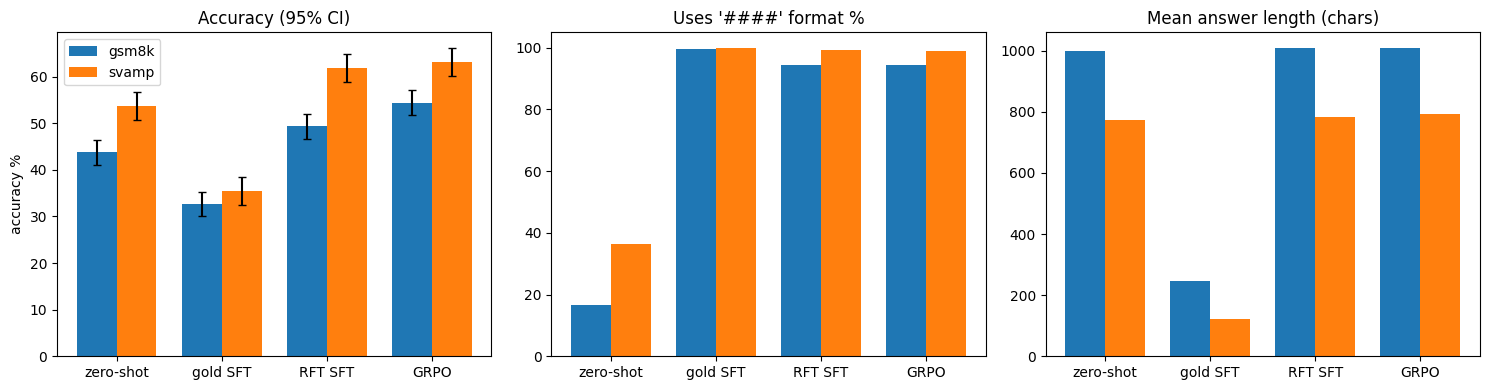

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
w = 0.38
for j, d in enumerate(DATASETS):
    t = table[table.dataset == d]
    ax[0].bar(np.arange(len(MODELS)) + (j - 0.5) * w, t.accuracy, w, label=d,
              yerr=[t.accuracy - t.ci_low, t.ci_high - t.accuracy], capsize=3)
ax[0].set_xticks(range(len(MODELS))); ax[0].set_xticklabels(MODELS); ax[0].set_ylabel("accuracy %"); ax[0].set_title("Accuracy (95% CI)"); ax[0].legend()
for j, d in enumerate(DATASETS):
    t = table[table.dataset == d]
    ax[1].bar(np.arange(len(MODELS)) + (j - 0.5) * w, t.format_rate, w, label=d)
    ax[2].bar(np.arange(len(MODELS)) + (j - 0.5) * w, t.mean_chars, w, label=d)
for a, title in zip(ax[1:], ["Uses '####' format %", "Mean answer length (chars)"]):
    a.set_xticks(range(len(MODELS))); a.set_xticklabels(MODELS); a.set_title(title)
fig.tight_layout(); fig.savefig(OUT_DIR / "accuracy.png", dpi=120); plt.show()

## Paired comparison
For each pair (A → B): **fixed** = A wrong, B right; **broken** = A right, B wrong. McNemar exact p-value on the discordant pairs; Δ CI from the same bootstrap resamples.

In [4]:
PAIRS = [("zero-shot", "gold SFT"), ("zero-shot", "RFT SFT"), ("zero-shot", "GRPO"), ("gold SFT", "RFT SFT"), ("RFT SFT", "GRPO")]
rows = []
for d in DATASETS:
    for a, b in PAIRS:
        ca, cb = preds[d][a].correct.to_numpy(), preds[d][b].correct.to_numpy()
        fixed, broken = int((~ca & cb).sum()), int((ca & ~cb).sum())
        delta = boot[d][MODELS.index(b)] - boot[d][MODELS.index(a)]
        rows.append(dict(dataset=d, A=a, B=b, delta=100 * (cb.mean() - ca.mean()), ci_low=100 * np.percentile(delta, 2.5),
                         ci_high=100 * np.percentile(delta, 97.5), fixed=fixed, broken=broken,
                         p_mcnemar=binomtest(fixed, fixed + broken, 0.5).pvalue if fixed + broken else 1.0))
pairs = pd.DataFrame(rows)
pairs.round(3).to_csv(OUT_DIR / "pairs.csv", index=False)
pairs.round(3)

,dataset,A,B,delta,ci_low,ci_high,fixed,broken,p_mcnemar
0,gsm8k,zero-shot,gold SFT,-11.069,-14.177,-8.036,137,283,0.000
1,gsm8k,zero-shot,RFT SFT,5.610,2.957,8.264,193,119,0.000
2,gsm8k,zero-shot,GRPO,10.614,7.961,13.343,232,92,0.000
3,gsm8k,gold SFT,RFT SFT,16.679,13.723,19.712,326,106,0.000
4,gsm8k,RFT SFT,GRPO,5.004,2.727,7.354,155,89,0.000
5,svamp,zero-shot,gold SFT,-18.200,-21.600,-14.800,75,257,0.000
6,svamp,zero-shot,RFT SFT,8.200,5.100,11.300,168,86,0.000
7,svamp,zero-shot,GRPO,9.500,6.300,12.600,180,85,0.000
8,svamp,gold SFT,RFT SFT,26.400,23.100,29.900,315,51,0.000
9,svamp,RFT SFT,GRPO,1.300,-1.500,4.100,106,93,0.395


## How many of the 4 models solve each problem

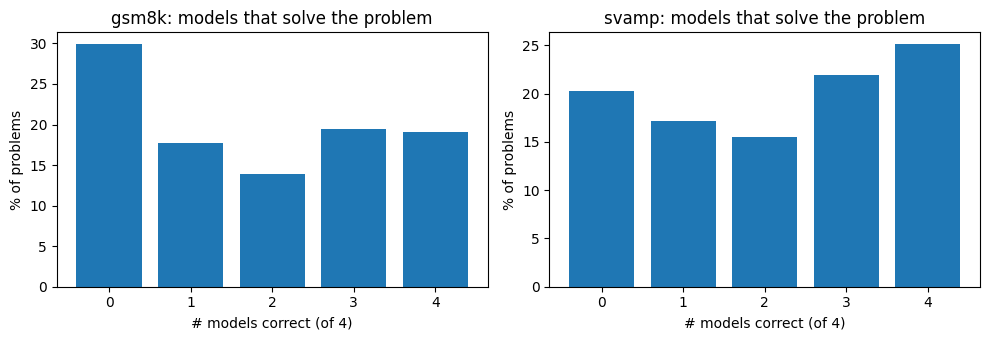

,gsm8k,svamp
0 models,394,203
1 models,233,172
2 models,184,155
3 models,257,219
4 models,251,251


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
solved = {}
for a, d in zip(ax, DATASETS):
    k = np.sum([preds[d][m].correct.to_numpy() for m in MODELS], axis=0)
    solved[d] = np.bincount(k, minlength=len(MODELS) + 1)
    a.bar(range(len(MODELS) + 1), 100 * solved[d] / len(k)); a.set_title(f"{d}: models that solve the problem"); a.set_xlabel("# models correct (of 4)"); a.set_ylabel("% of problems")
fig.tight_layout(); fig.savefig(OUT_DIR / "solved_by.png", dpi=120); plt.show()
pd.DataFrame(solved, index=[f"{i} models" for i in range(len(MODELS) + 1)])

In [6]:
(OUT_DIR / "metrics.json").write_text(json.dumps({"accuracy": table.round(2).to_dict("records"), "pairs": pairs.round(4).to_dict("records")}, indent=2))
table.pivot(index="model", columns="dataset", values="accuracy").loc[MODELS].round(1)

dataset,gsm8k,svamp
model,,
zero-shot,43.7,53.7
gold SFT,32.7,35.5
RFT SFT,49.4,61.9
GRPO,54.4,63.2
